# Heart Disease Prediction Using Machine Learning

## 1. Introduction

This project aims to predict the presence or absence of heart disease using clinical data from the UCI Cleveland Heart Disease dataset.

Two machine learning algorithms, Logistic Regression and Random Forest, will be trained and compared.

The models will be evaluated using Accuracy, Precision, Recall, F1-score, and Confusion Matrix.

## Research Question

How effectively can Logistic Regression and Random Forest classify the presence or absence of heart disease using clinical attributes?

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

##### Load Dataset

In [2]:
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'num'
]

df = pd.read_csv(
    'data/processed.cleveland.data',
    header=None,
    names=columns,
    na_values='?',
    skipinitialspace=True
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Dataset Inspection

In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num       

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


### 2. Data Cleaning

The dataset was inspected to identify missing values and duplicate records.

Missing values represented by '?' were converted into NaN during data loading.

Numerical and categorical missing values will be handled using median and most frequent value imputation, respectively, within the preprocessing pipeline.

Duplicate records will also be checked.

In [4]:
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Shape After Removing Duplicates:", df.shape)

Duplicate Records: 0
Shape After Removing Duplicates: (303, 14)


### 3. Target Variable Conversion

The original target variable is named 'num' and contains values from 0 to 4.

For binary classification:

- 0 represents no heart disease.
- Values 1, 2, 3, and 4 represent the presence of heart disease.

Therefore, the target variable will be converted into binary form.

In [5]:
df['target'] = (df['num'] > 0).astype(int)

print("Target Distribution:")
print(df['target'].value_counts())

print("\nTarget Percentage:")
print(df['target'].value_counts(normalize=True) * 100)

Target Distribution:
target
0    164
1    139
Name: count, dtype: int64

Target Percentage:
target
0    54.125413
1    45.874587
Name: proportion, dtype: float64


## Separate Features and Target

In [6]:
X = df.drop(columns=['num', 'target'])
y = df['target']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature Shape: (303, 13)
Target Shape: (303,)

Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


### Identify Numerical and Categorical Features

In [7]:
numerical_features = [
    'age', 'trestbps', 'chol', 'thalach', 'oldpeak'
]

categorical_features = [
    'sex', 'cp', 'fbs', 'restecg', 'exang',
    'slope', 'ca', 'thal'
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical Features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


### 4. Train-Test Split

The dataset will be divided into 80% training data and 20% testing data.

Stratified sampling will be used to maintain the proportion of both target classes in the training and testing sets.

A fixed random state will ensure reproducibility.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (242, 13)
Testing Data: (61, 13)

Training Target Distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing Target Distribution:
target
0    33
1    28
Name: count, dtype: int64


### 5. Data Preprocessing and Feature Engineering

Numerical features will be imputed using the median and scaled using StandardScaler.

Categorical features will be imputed using the most frequent value and transformed using One-Hot Encoding.

The preprocessing pipeline will be fitted only on the training data to prevent data leakage.

In [9]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

### 6. Model Training

### 6.1 Logistic Regression

Logistic Regression is selected as the baseline classification model because it is simple and interpretable.

It is suitable for binary classification and can estimate the probability of heart disease.

In [10]:
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


### 6.2 Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees.

It can capture nonlinear relationships and feature interactions.

It will be compared with Logistic Regression to examine the performance of a tree-based ensemble model.

In [11]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


## 7. Model Evaluation

Both models will be evaluated using the same test dataset.

The evaluation metrics are:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Recall is particularly important because failing to identify a patient with heart disease may be a serious concern.

In [12]:
models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.885246,0.83871,0.928571,0.881356
1,Random Forest,0.868852,0.81250,0.928571,0.866667


### Confusion Matrix

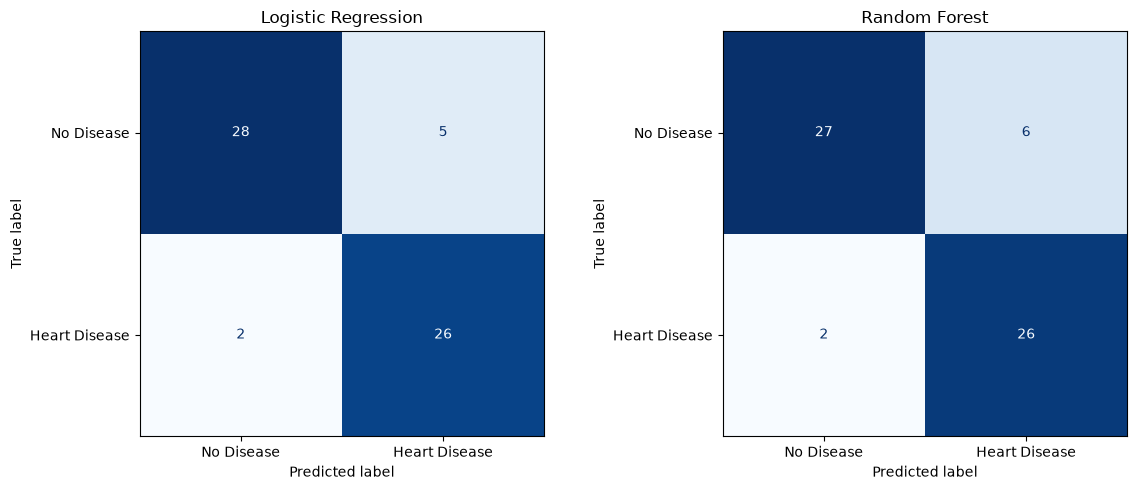

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Disease', 'Heart Disease']
    )

    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Model Comparison

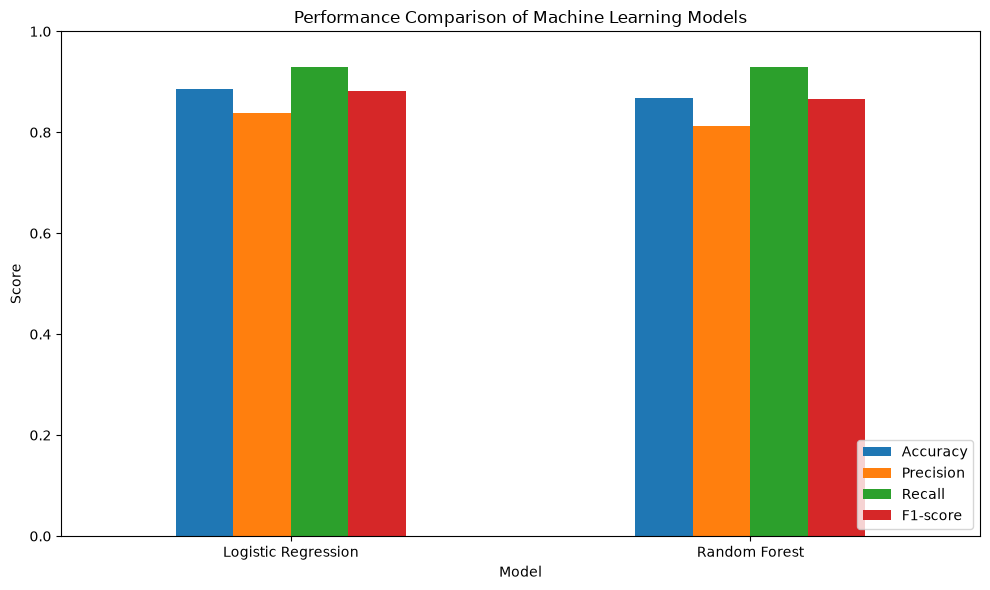

In [14]:
results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Performance Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 8. Experimental Findings and Future Improvements

The experimental results show that Logistic Regression achieved an accuracy of 88.52%, while Random Forest achieved 86.89%. Logistic Regression also obtained higher precision (83.87%) and F1-score (88.14%) compared to Random Forest. Both models achieved the same recall of 92.86%, correctly identifying 26 out of 28 actual heart disease cases. The confusion matrices show that both models produced two false negatives, while Logistic Regression produced fewer false positives than Random Forest. Overall, Logistic Regression performed slightly better on this test set. With more time, I would apply stratified cross-validation, perform hyperparameter tuning, and evaluate the models on an independent external dataset to obtain a more reliable assessment.